In [1]:
import tensorflow as tf
import os, shutil, tarfile

url = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"

# Just download — no more relying on Keras to auto-extract
archive_path = tf.keras.utils.get_file(
    "aclImdb_v1.tar.gz", origin=url, cache_dir='.', cache_subdir=''
)

# Extract it ourselves
if not os.path.exists('aclImdb'):
    print("Extracting...")
    with tarfile.open(archive_path) as tar:
        tar.extractall(path='.')
    print("Done extracting.")

dataset_dir = os.path.join('.', 'aclImdb')
print("Folders:", os.listdir(dataset_dir))

# Remove the 50,000 unlabeled reviews we don't need
unsup_dir = os.path.join(dataset_dir, 'train', 'unsup')
if os.path.exists(unsup_dir):
    shutil.rmtree(unsup_dir)
    print("Removed unsup folder")

84125825/84125825 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Extracting...


/tmp/ipykernel_2153/3254750102.py:15: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path='.')


Done extracting.
Folders: ['imdb.vocab', 'train', 'README', 'imdbEr.txt', 'test']
Removed unsup folder


In [2]:
import pandas as pd

def load_dataset(directory):
    reviews, sentiments = [], []
    for label_type, label_value in [('pos', 1), ('neg', 0)]:
        folder = os.path.join(directory, label_type)
        for fname in os.listdir(folder):
            if fname.endswith('.txt'):
                with open(os.path.join(folder, fname), encoding='utf-8') as f:
                    reviews.append(f.read())
                sentiments.append(label_value)
    df = pd.DataFrame({'review': reviews, 'sentiment': sentiments})
    return df.sample(frac=1, random_state=42).reset_index(drop=True)  # shuffle

train_df = load_dataset(os.path.join(dataset_dir, 'train'))
test_df = load_dataset(os.path.join(dataset_dir, 'test'))

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
train_df.head()

Train shape: (25000, 2)
Test shape: (25000, 2)


,review,sentiment
0,"I remember trying a few minutes of this film, ...",1
1,"ok. for starters, taxi driver is amazing. this...",0
2,Roman Polanski is considered as one of the mos...,1
3,If you like to comment on films where the scri...,0
4,You may consider a couple of facts in the disc...,0


In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
SAVE_DIR = '/content/drive/MyDrive/sentiment-analysis-lstm/data'
os.makedirs(SAVE_DIR, exist_ok=True)

train_df.to_csv(f'{SAVE_DIR}/train.csv', index=False)
test_df.to_csv(f'{SAVE_DIR}/test.csv', index=False)
print("Saved to Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved to Drive.


**PREPROCESSING**

In [4]:
import re

def clean_text(text):
    text = re.sub(r'<br\s*/?>', ' ', text)     # remove HTML line-break tags
    text = re.sub(r'[^a-zA-Z\s]', '', text)     # keep only letters and spaces
    text = re.sub(r'\s+', ' ', text).strip()    # collapse extra spaces
    return text.lower()

train_df['clean_review'] = train_df['review'].apply(clean_text)
test_df['clean_review'] = test_df['review'].apply(clean_text)

print("BEFORE:", train_df['review'].iloc[0][:150])
print("\nAFTER: ", train_df['clean_review'].iloc[0][:150])

BEFORE: I remember trying a few minutes of this film, I'm very surprised I didn't watch all of it, from director Steve Gordon, his only film directed before d

AFTER:  i remember trying a few minutes of this film im very surprised i didnt watch all of it from director steve gordon his only film directed before dying 


**split training data into train/validation (90/10)**

In [5]:
from sklearn.model_selection import train_test_split

train_texts, val_texts, train_labels, val_labels = train_test_split(
    train_df['clean_review'].values,
    train_df['sentiment'].values,
    test_size=0.1,
    random_state=42,
    stratify=train_df['sentiment'].values   # keeps the 50/50 pos-neg balance in both pieces
)

print("Train:", len(train_texts), "| Validation:", len(val_texts))

Train: 22500 | Validation: 2500


***tokenize and pad:***

In [6]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

VOCAB_SIZE = 10000
MAX_LEN = 200

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer.fit_on_texts(train_texts)   # build vocabulary ONLY from training text

X_train = pad_sequences(tokenizer.texts_to_sequences(train_texts), maxlen=MAX_LEN, padding='post', truncating='post')
X_val   = pad_sequences(tokenizer.texts_to_sequences(val_texts), maxlen=MAX_LEN, padding='post', truncating='post')
X_test  = pad_sequences(tokenizer.texts_to_sequences(test_df['clean_review'].values), maxlen=MAX_LEN, padding='post', truncating='post')

y_train, y_val, y_test = train_labels, val_labels, test_df['sentiment'].values

print("X_train shape:", X_train.shape)
print("X_val shape:  ", X_val.shape)
print("X_test shape: ", X_test.shape)
print("\nExample text:    ", train_texts[0][:80])
print("Example as numbers:", X_train[0][:15])

X_train shape: (22500, 200)
X_val shape:   (2500, 200)
X_test shape:  (25000, 200)

Example text:     yes ill admit it i believed all the hype surrounding this piece of work about th
Example as numbers: [ 412  525  939    9   10 2388   31    2 3326 3261   11  406    5  159
   42]


In [8]:
import pickle

with open('/content/drive/MyDrive/sentiment-analysis-lstm/tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

print("Tokenizer saved.")

Tokenizer saved.


***build the model:***

In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dense, Dropout

EMBEDDING_DIM = 128

model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.build(input_shape=(None, MAX_LEN))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,382,977 (5.28 MB)

 Trainable params: 1,382,977 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

***train the model:***

In [14]:
import tensorflow as tf
import numpy as np
import pickle
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

SAVE_PATH = '/content/drive/MyDrive/sentiment-analysis-lstm'


class PercentLogger(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        print(f"Epoch {epoch+1:>2} | "
              f"train acc: {logs['accuracy']*100:6.2f}% | "
              f"val acc: {logs['val_accuracy']*100:6.2f}% | "
              f"train loss: {logs['loss']:.4f} | "
              f"val loss: {logs['val_loss']:.4f}")


callbacks = [
    PercentLogger(),
    EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, verbose=1),
    ModelCheckpoint(f'{SAVE_PATH}/best_model.keras', monitor='val_accuracy', save_best_only=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, min_lr=1e-6, verbose=1),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64,
    callbacks=callbacks,
    verbose=0
)

with open(f'{SAVE_PATH}/history.pkl', 'wb') as f:
    pickle.dump(history.history, f)

h = history.history
best = int(np.argmax(h['val_accuracy']))

print("\n" + "=" * 55)
print("TRAINING SUMMARY")
print("=" * 55)
print(f"Epochs run          : {len(h['accuracy'])}")
print(f"Best epoch          : {best + 1}")
print(f"Best val accuracy   : {h['val_accuracy'][best]*100:.2f}%")
print(f"Train acc (best ep) : {h['accuracy'][best]*100:.2f}%")
print(f"Overfitting gap     : {(h['accuracy'][best] - h['val_accuracy'][best])*100:+.2f}%")
print("=" * 55)
print("Model and history saved to Drive.")

Epoch  1 | train acc:  74.92% | val acc:  84.08% | train loss: 0.5034 | val loss: 0.3852
Epoch  2 | train acc:  88.46% | val acc:  84.92% | train loss: 0.3094 | val loss: 0.4189

Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
Epoch  3 | train acc:  92.79% | val acc:  85.60% | train loss: 0.2069 | val loss: 0.3389
Epoch  4 | train acc:  94.79% | val acc:  84.56% | train loss: 0.1560 | val loss: 0.3590

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Epoch  5 | train acc:  96.83% | val acc:  85.60% | train loss: 0.1044 | val loss: 0.4214

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 3.

TRAINING SUMMARY
Epochs run          : 5
Best epoch          : 3
Best val accuracy   : 85.60%
Train acc (best ep) : 92.79%
Overfitting gap     : +7.19%
Model and history saved to Drive.


***Evaluation***

***accuracy and loss graphs:***

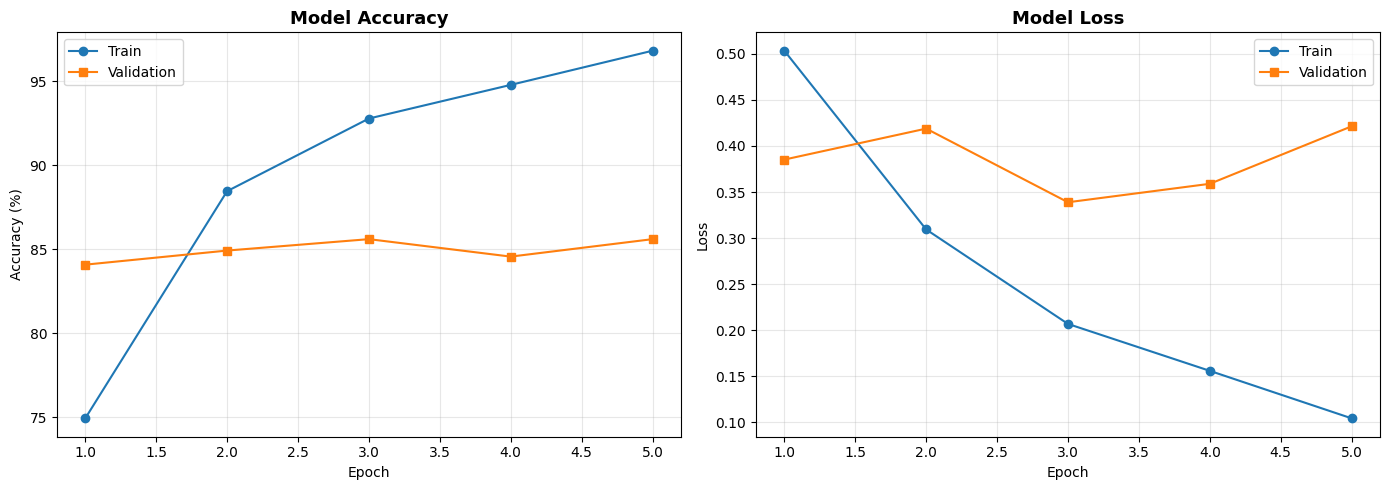

In [15]:
import matplotlib.pyplot as plt
import numpy as np

h = history.history
epochs = range(1, len(h['accuracy']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, [a*100 for a in h['accuracy']], 'o-', label='Train')
axes[0].plot(epochs, [a*100 for a in h['val_accuracy']], 's-', label='Validation')
axes[0].set_title('Model Accuracy', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy (%)')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs, h['loss'], 'o-', label='Train')
axes[1].plot(epochs, h['val_loss'], 's-', label='Validation')
axes[1].set_title('Model Loss', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{SAVE_PATH}/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

***evaluate on the 25,000 test reviews:***

FINAL TEST SET RESULTS (25,000 unseen reviews)
Test accuracy : 83.90%
Test loss     : 0.3788
ROC-AUC score : 92.16%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative     0.8155    0.8761    0.8447     12500
    Positive     0.8661    0.8018    0.8328     12500

    accuracy                         0.8390     25000
   macro avg     0.8408    0.8390    0.8387     25000
weighted avg     0.8408    0.8390    0.8387     25000



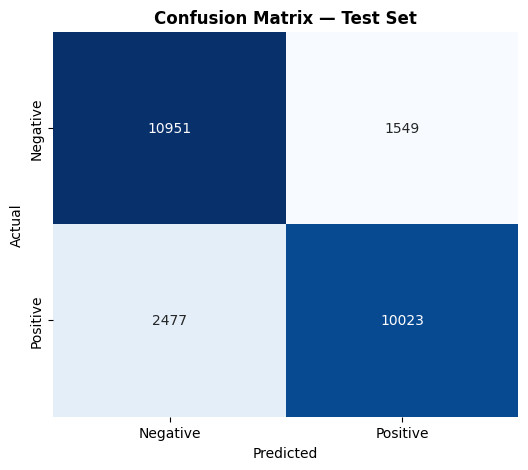

In [16]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
import seaborn as sns

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

y_prob = model.predict(X_test, verbose=0).flatten()
y_pred = (y_prob > 0.5).astype(int)

print("=" * 55)
print("FINAL TEST SET RESULTS (25,000 unseen reviews)")
print("=" * 55)
print(f"Test accuracy : {test_acc*100:.2f}%")
print(f"Test loss     : {test_loss:.4f}")
print(f"ROC-AUC score : {roc_auc_score(y_test, y_prob)*100:.2f}%")
print("=" * 55)

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive'], digits=4))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.title('Confusion Matrix — Test Set', fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.savefig(f'{SAVE_PATH}/confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

***Testing on Custom Sentences***

***the prediction function:***

In [18]:
def predict_sentiment(texts, show_details=True):
    if isinstance(texts, str):
        texts = [texts]

    cleaned = [clean_text(t) for t in texts]
    seqs = tokenizer.texts_to_sequences(cleaned)
    padded = pad_sequences(seqs, maxlen=MAX_LEN, padding='post', truncating='post')
    probs = model.predict(padded, verbose=0).flatten()

    results = []
    for text, prob in zip(texts, probs):
        label = "POSITIVE" if prob > 0.5 else "NEGATIVE"
        confidence = prob if prob > 0.5 else 1 - prob
        results.append({'text': text, 'label': label, 'score': prob})

        if show_details:
            bar = "█" * int(prob * 30)
            print(f'"{text[:70]}"')
            print(f"   → {label}  (confidence: {confidence*100:.2f}%)")
            print(f"   positive score: {prob*100:.2f}%  [{bar:<30}]")
            print()

    return results


samples = [
    "This movie was absolutely fantastic! Best film I've seen all year.",
    "Terrible acting, boring plot. Complete waste of time.",
    "The cinematography was stunning and the soundtrack was beautiful.",
    "I fell asleep halfway through. Nothing happens.",
    "This movie was not good at all.",
    "It wasn't bad, actually I enjoyed it more than I expected.",
    "The film had some issues with pacing, but the performances were incredible.",
]

_ = predict_sentiment(samples)

"This movie was absolutely fantastic! Best film I've seen all year."
   → POSITIVE  (confidence: 96.50%)
   positive score: 96.50%  [████████████████████████████  ]

"Terrible acting, boring plot. Complete waste of time."
   → NEGATIVE  (confidence: 99.76%)
   positive score: 0.24%  [                              ]

"The cinematography was stunning and the soundtrack was beautiful."
   → POSITIVE  (confidence: 74.65%)
   positive score: 74.65%  [██████████████████████        ]

"I fell asleep halfway through. Nothing happens."
   → NEGATIVE  (confidence: 94.73%)
   positive score: 5.27%  [█                             ]

"This movie was not good at all."
   → NEGATIVE  (confidence: 52.70%)
   positive score: 47.30%  [██████████████                ]

"It wasn't bad, actually I enjoyed it more than I expected."
   → POSITIVE  (confidence: 70.07%)
   positive score: 70.07%  [█████████████████████         ]

"The film had some issues with pacing, but the performances were incred"
   → NEGA

***save everything:***

In [19]:
import json, pickle, os

os.makedirs(SAVE_PATH, exist_ok=True)

model.save(f'{SAVE_PATH}/sentiment_lstm_model.keras')

with open(f'{SAVE_PATH}/tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

config = {
    'VOCAB_SIZE': VOCAB_SIZE,
    'MAX_LEN': MAX_LEN,
    'EMBEDDING_DIM': EMBEDDING_DIM,
    'architecture': 'Embedding -> Bidirectional LSTM(64) -> Dropout -> Dense(32) -> Dense(1)',
    'test_accuracy': float(test_acc),
    'test_loss': float(test_loss),
    'test_roc_auc': float(roc_auc_score(y_test, y_prob)),
}
with open(f'{SAVE_PATH}/config.json', 'w') as f:
    json.dump(config, f, indent=2)

print("Saved:", sorted(os.listdir(SAVE_PATH)))

Saved: ['best_model.keras', 'config.json', 'confusion_matrix.png', 'data', 'history.pkl', 'sentiment_lstm_model.keras', 'tokenizer.pkl', 'training_curves.png']


***verify the save actually works.***

In [20]:
from tensorflow.keras.models import load_model

test_sentence = "This movie was absolutely fantastic! Best film I've seen all year."

before = predict_sentiment(test_sentence, show_details=False)[0]['score']

loaded_model = load_model(f'{SAVE_PATH}/sentiment_lstm_model.keras')
with open(f'{SAVE_PATH}/tokenizer.pkl', 'rb') as f:
    loaded_tokenizer = pickle.load(f)
with open(f'{SAVE_PATH}/config.json') as f:
    cfg = json.load(f)

seq = loaded_tokenizer.texts_to_sequences([clean_text(test_sentence)])
padded = pad_sequences(seq, maxlen=cfg['MAX_LEN'], padding='post', truncating='post')
after = loaded_model.predict(padded, verbose=0).flatten()[0]

print(f"Before save : {before*100:.4f}%")
print(f"After load  : {after*100:.4f}%")
print("MATCH:", np.isclose(before, after))

Before save : 96.5015%
After load  : 96.5015%
MATCH: True
